# M03-6 | 只量化一部分、組合多個 Quantizer、標註順序

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/m03_quantizer_api/06_partial_quantization.ipynb)

真實的後端很少把整個模型一次量化完：

- 某些層對量化很敏感，要留在 fp32（M05 的 mixed precision）。
- 某些 op 硬體不支援，只能 fallback 到 CPU（M10）。
- 不同種類的 op 由不同的 Quantizer 負責。

這本 notebook 的三段：

- **A.** 局部量化：用 module 名稱決定哪些 conv 要量化，看 fp32 與 int8 的交界長出什麼。
- **B.** `ComposableQuantizer`：一個 Quantizer 管一類 op，以及它禁止的事。
- **C.** 標註順序：大 pattern（conv + relu）要先標，小 pattern（conv）才不會搶走 node。

In [ ]:
#| include: false
# 在 Google Colab 上執行時：下載本教材的程式並安裝套件（第一次約需幾分鐘）。
# 在自己的電腦上執行時（環境見 README），這一格什麼都不做。
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # 讓 notebook 能 import 本教材的 common/
    os.chdir(f"{repo}/m03_quantizer_api")

In [1]:
import copy

import torch
from torch.fx import Node

from common.data import calibration_batches
from common.graph_utils import observer_nodes, qdq_nodes
from common.models import example_inputs, get_model
from common.pt2e import (
    ANNOTATION_KEY,
    ComposableQuantizer,
    QuantizationAnnotation,
    Quantizer,
    annotate_input_qspec_map,
    annotate_output_qspec,
    convert_pt2e,
    export_module,
    get_module_name_filter,
    prepare_pt2e,
    quiet,
)
from common.qspecs import act_spec, weight_spec
from common.viz import draw, draw_stages, table

quiet()
_ = torch.manual_seed(0)
CONV2D = torch.ops.aten.conv2d.default
RELU = torch.ops.aten.relu.default
ADD = torch.ops.aten.add.Tensor

三段共用的規則式 Quantizer。它們都照 M03-3 的寫法：用 `node.target` 找 op，已經被標過（`_annotated`）的 node 不動。

In [2]:
def find(gm, target):
    return [n for n in gm.graph.nodes if n.op == "call_function" and n.target == target]


def done(*nodes):
    """這些 node 裡有沒有已經被標過的。"""
    return any((a := n.meta.get(ANNOTATION_KEY)) is not None and a._annotated for n in nodes)


def label_conv(conv, out):
    """conv 的 activation 與 weight 輸入邊，加上輸出標籤（貼在 out：conv 自己，或後面的 relu）。"""
    annotate_input_qspec_map(conv, conv.args[0], act_spec())
    annotate_input_qspec_map(conv, conv.args[1], weight_spec())
    annotate_output_qspec(out, act_spec())
    for node in (conv, out):
        node.meta[ANNOTATION_KEY]._annotated = True


class RuleQuantizer(Quantizer):
    def validate(self, model):
        pass


class ConvQuantizer(RuleQuantizer):
    """量化 conv2d。include 是 node -> bool 的函式，決定哪些 conv 要量化（預設全部）。"""

    def __init__(self, include=None):
        self.include = include

    def annotate(self, model):
        for conv in find(model, CONV2D):
            if not done(conv) and (self.include is None or self.include(conv)):
                label_conv(conv, conv)
        return model


class ConvReluQuantizer(RuleQuantizer):
    """量化 conv + relu：輸出標籤貼在 relu，conv 與 relu 之間不量化。"""

    def annotate(self, model):
        for relu in find(model, RELU):
            conv = relu.args[0]
            # conv 的輸出還有別的使用者時，conv + relu 就不是一個獨立的 pattern
            if conv.op == "call_function" and conv.target == CONV2D and len(conv.users) == 1 and not done(conv, relu):
                label_conv(conv, relu)
        return model


class AddQuantizer(RuleQuantizer):
    """量化 add 的 activation 輸入與輸出（排除純量與模型常數）。"""

    def annotate(self, model):
        for add in find(model, ADD):
            inputs = [a for a in add.args[:2] if isinstance(a, Node) and a.op != "get_attr"]
            if inputs and not done(add):
                for a in inputs:
                    annotate_input_qspec_map(add, a, act_spec())
                annotate_output_qspec(add, act_spec())
                add.meta[ANNOTATION_KEY]._annotated = True
        return model

## A. 局部量化：用 module 名稱決定哪些 conv 要量化

`tiny` 模型有三段：`stem`、`block`、`head_conv`。torchao 的 `get_module_name_filter("stem")` 回傳一個 `node -> bool` 的函式：
這個 node 是不是來自名叫 `stem` 的子模組（看 `node.meta["nn_module_stack"]`）。把它傳給 `ConvQuantizer` 當 `include`，不在名單內的 conv 就不貼標籤。

In [3]:
def calibrate(prepared):
    with torch.no_grad():
        for batch in calibration_batches(n=64, batch_size=16):
            prepared(*batch)


model = get_model("tiny").eval()
gm_tiny = export_module(model, example_inputs(8))
configs = [("全部 conv", None)] + [(f"只量化 {name}", get_module_name_filter(name)) for name in ("stem", "block", "head_conv")]
rows, converted = [], {}
for title, include in configs:
    prepared = prepare_pt2e(copy.deepcopy(gm_tiny), ConvQuantizer(include))
    n_obs = len(observer_nodes(prepared))
    calibrate(prepared)
    converted[title] = convert_pt2e(prepared)
    rows.append([title, n_obs, len(qdq_nodes(converted[title]))])
table(rows, ["設定", "observer 數", "q/dq 數"])

設定,observer 數,q/dq 數
全部 conv,12,20
只量化 stem,3,5
只量化 block,6,10
只量化 head_conv,3,5


不在名單內的 conv 沒有標籤，`prepare_pt2e` 不替它插任何 observer，它和後面的 op 都留在 fp32。
把「只量化 stem」convert 之後的 op 排成一行（q = quantize、dq = dequantize），看 int8 與 fp32 的交界：

In [4]:
def sequence(gm):
    def short(n):
        t = str(n.target)
        return "dq" if "dequantize" in t else "q" if "quantize" in t else n.name.rstrip("_0123456789")
    return " ".join(short(n) for n in gm.graph.nodes if n.op == "call_function")


chain = sequence(converted["只量化 stem"])
print(chain)

dq q dq conv2d q dq relu max_pool2d conv2d relu conv2d add relu max_pool2d conv2d relu adaptive_avg_pool2d flatten linear


In [5]:
assert chain.startswith("dq q dq conv2d q dq relu")
assert "q" not in chain.split("relu", 1)[1].split()  # stem 之後再也沒有 q/dq

- 最前面單獨一個 `dq` 是 stem 的 weight：它已經預先量化成 int8 常數，執行時只剩 dequantize。
- 接著 `q dq conv2d q dq`：stem 的 conv 輸入與輸出各一對 q/dq。之後全部是 fp32。

q/dq 只出現在被量化的 conv 前後，這就是 fp32 與 int8 的交界。交界越多，q/dq 的開銷越大，所以後端偏好整段連續量化。
後端把這種做法包成 `set_module_name` 之類的設定 API，M03-7 會看到。

## B. ComposableQuantizer：一個 Quantizer 管一類 op

`ComposableQuantizer([q1, q2, …])` 依序呼叫每個 Quantizer 的 `annotate`。每個 Quantizer 只專心管自己那類 op，組合起來涵蓋整個模型。
在 residual 模型上，先只用 `ConvQuantizer`，再加上 `AddQuantizer`：

In [6]:
gm_res = export_module(get_model("residual").eval(), example_inputs(4))
only_conv = prepare_pt2e(copy.deepcopy(gm_res), ConvQuantizer())
composed = prepare_pt2e(copy.deepcopy(gm_res), ComposableQuantizer([ConvQuantizer(), AddQuantizer()]))
print("只有 ConvQuantizer：observer", len(observer_nodes(only_conv)), "個")
print("ConvQuantizer + AddQuantizer：observer", len(observer_nodes(composed)), "個")
assert len(observer_nodes(composed)) == len(observer_nodes(only_conv)) + 1

只有 ConvQuantizer：observer 6 個
ConvQuantizer + AddQuantizer：observer 7 個


多出來的是哪一個？只畫 add 附近，左邊只有 `ConvQuantizer`，右邊加上 `AddQuantizer`，綠框是新長出來的 observer：

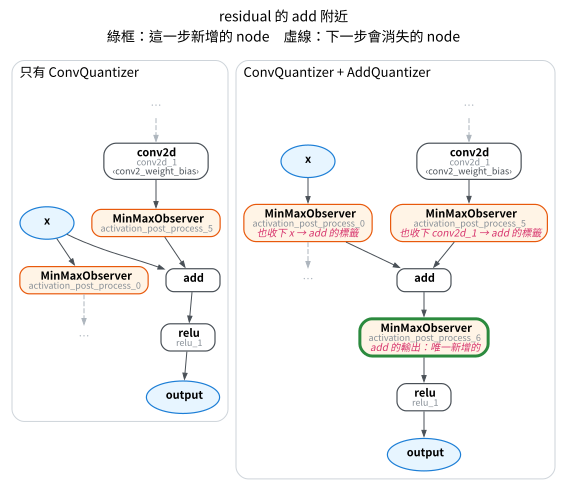

In [7]:
add = next(n for n in composed.graph.nodes if n.target == ADD)
from_conv, from_x = add.args[0], add.args[1]  # add 的兩個輸入，現在都是 observer
draw_stages([(only_conv, "只有 ConvQuantizer"), (composed, "ConvQuantizer + AddQuantizer")], focus="add", hops=2,
            notes=[{}, {from_conv.name: "也收下 conv2d_1 → add 的標籤", from_x.name: "也收下 x → add 的標籤",
                        next(iter(add.users)).name: "add 的輸出：唯一新增的"}],
            title="residual 的 add 附近")

In [8]:
conv = next(n for n in composed.graph.nodes if n.target == CONV2D)
assert from_x is conv.args[0]  # add 吃的 x，和第一個 conv 吃的是同一個 observer
assert from_conv.args[0].name == "conv2d_1"  # add 吃的 conv 輸出，是 conv2d_1 原有的輸出 observer

只多了 add 的輸出一個。add 的兩條輸入邊也貼了標籤，卻沒有各自長出 observer，而是併進既有的 observer：

- **`conv2d_1 → add`**：`ConvQuantizer` 已經在 `conv2d_1` 的輸出貼了標籤，兩張標籤屬性相同，共用同一個 observer。
- **`x → add`**：左圖的 add 直接吃原本的 `x`（不量化）；右圖改吃 `x` 原有的 observer，也就是第一個 conv 用的那個。兩條邊的標籤屬性相同，併成一個。

這就是 M03-4 的隱式共用：同一個 tensor 上屬性相同的標籤只量化一次。

`ComposableQuantizer` 禁止的事：在每個 Quantizer 的 `annotate` 之後，它檢查前面已經貼好的標籤有沒有被換掉或刪掉，有就報錯。
下面的 `MeddlingQuantizer` 把 conv 的標籤整個換成空標籤，排在 `ConvQuantizer` 後面：

In [9]:
class MeddlingQuantizer(RuleQuantizer):
    def annotate(self, model):
        for conv in find(model, CONV2D):
            conv.meta[ANNOTATION_KEY] = QuantizationAnnotation()
        return model


try:
    prepare_pt2e(copy.deepcopy(gm_res), ComposableQuantizer([ConvQuantizer(), MeddlingQuantizer()]))
    raised = None
except RuntimeError as e:
    raised = e
print("RuntimeError:", raised)
assert raised is not None

RuntimeError: Quantizer MeddlingQuantizer has changed annotations on node conv2d


所以後面的 Quantizer 只能補上還沒有標籤的 node，不能改別人的。每個 `annotate` 開頭檢查 `_annotated`（這裡的 `done()`），就是為了遵守這個約定。

## C. 標註順序：大 pattern 先標

`ConvReluQuantizer`（大 pattern）和 `ConvQuantizer`（小 pattern）都想標同一個 conv。誰先標，誰就拿走它。
同一個 conv → relu，兩種順序各 prepare 一次：

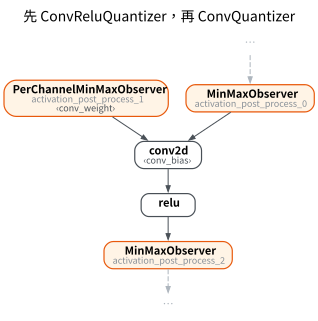

In [10]:
gm_cr = export_module(get_model("conv_relu").eval(), example_inputs(4))
big_first = prepare_pt2e(copy.deepcopy(gm_cr), ComposableQuantizer([ConvReluQuantizer(), ConvQuantizer()]))
draw(big_first, focus=["conv2d", "relu"], title="先 ConvReluQuantizer，再 ConvQuantizer")

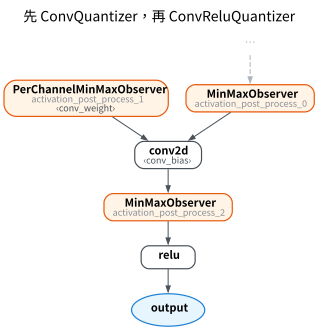

In [11]:
small_first = prepare_pt2e(copy.deepcopy(gm_cr), ComposableQuantizer([ConvQuantizer(), ConvReluQuantizer()]))
draw(small_first, focus=["conv2d", "relu"], title="先 ConvQuantizer，再 ConvReluQuantizer")

In [12]:
def observer_before_relu(gm):
    relu = next(n for n in gm.graph.nodes if n.target == RELU)
    return relu.args[0].op == "call_module"


print("大 pattern 先：conv 與 relu 之間有 observer？", observer_before_relu(big_first))
print("小 pattern 先：conv 與 relu 之間有 observer？", observer_before_relu(small_first))
assert not observer_before_relu(big_first) and observer_before_relu(small_first)

大 pattern 先：conv 與 relu 之間有 observer？ False
小 pattern 先：conv 與 relu 之間有 observer？ True


- **大 pattern 先**：`ConvReluQuantizer` 標了 conv 與 relu 並設 `_annotated`，`ConvQuantizer` 看到 conv 已被標過，跳過。量化點在 relu 之後，conv 與 relu 之間沒有 observer。
- **小 pattern 先**：`ConvQuantizer` 先拿走 conv（連輸出一起標），`ConvReluQuantizer` 發現 conv 已被標過，放棄。conv 與 relu 之間多了一個量化點，後端無法把兩者融成一個 kernel。

兩種順序都合法、都跑得動，只是結果不同。順序是 Quantizer 作者的責任：torchao 測試版 XNNPACKQuantizer 的 `STATIC_OPS`
依序是 `linear_relu`、`linear`、`conv_relu`、`conv`…，同樣是大的在前。

## 小結

- 局部量化：不貼標籤的 op 留在 fp32，交界處長出 q/dq。用 `get_module_name_filter` 依 module 名稱挑 node。
- `ComposableQuantizer` 依序呼叫多個 Quantizer；後面的只能補，不能改前面貼好的標籤。
- 標註順序決定結果：大 pattern 要排在小 pattern 前面。